# 5. Measuring accuracy

To know how well the engine reads your pages, measure it on pages whose text you know. The module scores text in C++, as the models' evaluation does:

- `text_errors(truths, predicted)` gives each pair's edit distance in characters and the truth's length in characters, then the same in words. Their sums give the character and word error rates, CER and WER.
- `char_confusions(truths, predicted)` aligns each pair by its fewest edits and counts which characters became which.

This notebook makes the letter harder to read in five ways (blur, noise, JPEG compression, low resolution, faded ink), measures each, and looks at which characters go wrong and how far a line's confidence tells you so. It ends with a function that measures any folder of scans with their texts.

In [1]:
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageFilter

import carbon_ocr
import helpers
import sample_pages

plt.rcParams["figure.dpi"] = 90
SET = helpers.model_set()
pages = sample_pages.make_all("data")
engine = carbon_ocr.Engine(SET)
letter = Image.open(pages["letter"])
truth = sample_pages.truth_text(pages["letter"])
truth_lines = sample_pages.truth(pages["letter"])["lines"]


def score(predicted, truths=None):
    """CER and WER of pages' texts against their truths (by default, the letter's)."""
    truths = truths or [truth] * len(predicted)
    e = carbon_ocr.text_errors(truths, predicted).sum(0)
    return e[0] / e[1], e[2] / e[3]


page = engine.ocr([np.asarray(letter)])[0]
print("the letter as drawn: CER {:.2%}, WER {:.2%}".format(*score([page["text"]])))

the letter as drawn: CER 0.00%, WER 0.00%


## Five ways to make a page harder

Each function takes the clean letter and a severity, and returns a grayscale page. The page's text stays the letter's.

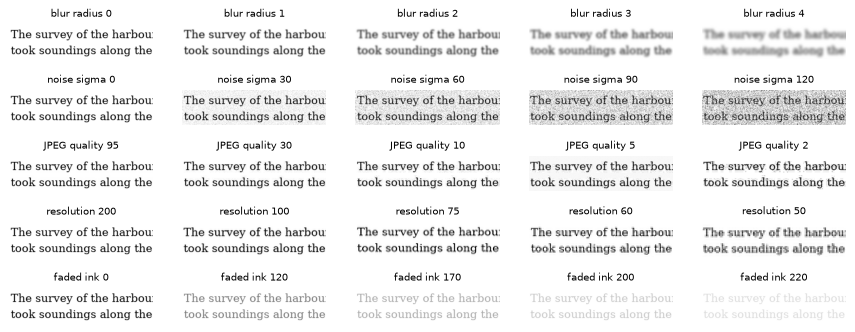

In [2]:
def blur(img, radius):
    return img.filter(ImageFilter.GaussianBlur(radius)) if radius else img


def noise(img, sigma, seed=0):
    a = np.asarray(img, np.float32) + np.random.default_rng(seed).normal(0, sigma, img.size[::-1])
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))


def jpeg(img, quality):
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=quality)
    return Image.open(io.BytesIO(buf.getvalue())).convert("L")


def resolution(img, dpi):  # the letter is drawn at 200 dpi
    w, h = img.size
    return img.resize((round(w * dpi / 200), round(h * dpi / 200)), Image.Resampling.LANCZOS)


def faded(img, ink):  # the ink's gray level, 0 black, on white paper
    a = np.asarray(img, np.float32)
    return Image.fromarray((ink + (255 - ink) * a / 255).astype(np.uint8))


SWEEPS = {
    "blur radius (px)": (blur, [0, 1, 2, 3, 4]),
    "noise sigma (levels)": (noise, [0, 30, 60, 90, 120]),
    "JPEG quality": (jpeg, [95, 30, 10, 5, 2]),
    "resolution (dpi)": (resolution, [200, 100, 75, 60, 50]),
    "faded ink (gray level)": (faded, [0, 120, 170, 200, 220]),
}
fig, axes = plt.subplots(len(SWEEPS), 5, figsize=(12, 4.6))
for row, (name, (f, levels)) in zip(axes, SWEEPS.items()):
    for ax, level in zip(row, levels):
        img = f(letter, level)
        y, x = img.size[1] / 2200, img.size[0] / 1700  # the same part of the page at any resolution
        crop = np.asarray(img)[round(338 * y):round(436 * y), round(155 * x):round(560 * x)]
        ax.imshow(crop, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{name.split(' (')[0]} {level}", fontsize=8)
        ax.set_axis_off()

In [3]:
results = {}
for name, (f, levels) in SWEEPS.items():
    images = [np.asarray(f(letter, level)) for level in levels]
    read = engine.ocr(images)  # each sweep's pages at once, over all the workers
    results[name] = [(level, page) for level, page in zip(levels, read)]
    print(name)
    for level, page in results[name]:
        cer, wer = score([page["text"]])
        print(f"   {level:5}  CER {cer:7.2%}  WER {wer:7.2%}  {len(page['lines']):2} lines")

blur radius (px)
       0  CER   0.00%  WER   0.00%  21 lines
       1  CER   0.07%  WER   0.00%  22 lines
       2  CER   0.07%  WER   0.39%  21 lines
       3  CER   0.22%  WER   1.18%  21 lines
       4  CER   2.99%  WER  15.69%  21 lines


noise sigma (levels)
       0  CER   0.00%  WER   0.00%  21 lines
      30  CER   0.00%  WER   0.00%  21 lines
      60  CER   0.15%  WER   0.39%  22 lines
      90  CER   0.36%  WER   1.96%  21 lines
     120  CER   8.97%  WER  26.67%  45 lines


JPEG quality
      95  CER   0.00%  WER   0.00%  21 lines
      30  CER   0.00%  WER   0.00%  21 lines
      10  CER   0.00%  WER   0.00%  21 lines
       5  CER   0.00%  WER   0.00%  21 lines
       2  CER   0.15%  WER   0.78%  21 lines


resolution (dpi)
     200  CER   0.00%  WER   0.00%  21 lines
     100  CER   0.00%  WER   0.00%  21 lines
      75  CER   0.07%  WER   0.00%  22 lines
      60  CER   0.00%  WER   0.00%  21 lines
      50  CER   0.36%  WER   1.57%  22 lines


faded ink (gray level)
       0  CER   0.00%  WER   0.00%  21 lines
     120  CER   0.00%  WER   0.00%  21 lines
     170  CER   0.00%  WER   0.00%  21 lines
     200  CER   0.00%  WER   0.00%  21 lines
     220  CER   0.15%  WER   0.78%  21 lines


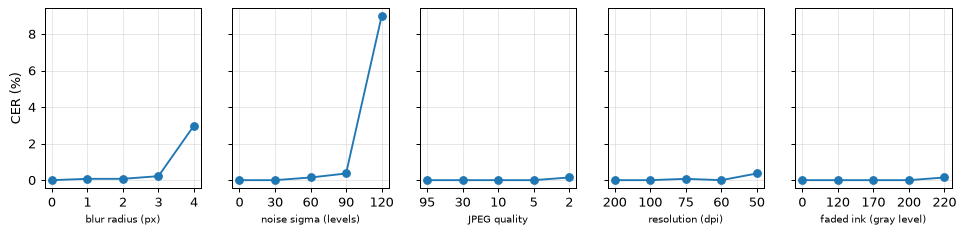

In [4]:
fig, axes = plt.subplots(1, len(SWEEPS), figsize=(13, 2.6), sharey=True)
for ax, (name, rows) in zip(axes, results.items()):
    ax.plot([str(level) for level, _ in rows], [100 * score([p["text"]])[0] for _, p in rows], "o-")
    ax.set_xlabel(name, fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("CER (%)");

The engine reads through most of this. On this page, JPEG compression down to quality 5, 60 dpi, and ink faded to a light gray cost it nothing or next to nothing. Its errors grow at the far ends: a blur of 4 px (a few per cent of the characters, and more of the words) and noise of σ 120, where the detector also finds lines in the noise itself. At 50 dpi, where a capital letter is about 6 px high, it still reads nearly every word. A clean drawn page is kinder than a real scan, so measure your own pages before you trust these numbers for them.

## Which characters go wrong

`char_confusions` aligns each line of text with its truth and counts the edits. Here it runs over every page of the sweeps above.

In [5]:
predicted = [p["text"] for rows in results.values() for _, p in rows]
c = carbon_ocr.char_confusions([truth] * len(predicted), predicted, top=15)
print(f"{c['chars']} characters of truth: {c['substitutions']} substituted, {c['insertions']} inserted, "
      f"{c['deletions']} deleted, in {c['distinct']} distinct edits\n")
print("truth  read   count")
for t, p, n in c["edits"]:
    print(f"{t!r:6} {p!r:6} {n:5}")

34300 characters of truth: 75 substituted, 100 inserted, 11 deleted, in 84 distinct edits

truth  read   count
''     '\n'      24
''     'b'       11
'•'    '*'        9
'.'    ','        6
'n'    'm'        5
''     'E'        4
''     'e'        4
''     'i'        4
' '    '\n'       4
'h'    'b'        4
'•'    '+'        4
''     ' '        3
''     '3'        3
''     'F'        3
''     'S'        3


An empty string on the truth's side is an insertion, and on the read side a deletion. Line breaks count as characters too: a line the engine splits or joins differently from the truth, or finds in the noise, shows up as a `'\n'` edit. Past those, the edits are what you would expect of a damaged page: the bullet read as an asterisk or a plus, a full stop as a comma, *n* as *m*, and stray letters read out of the heaviest noise.

## How far to trust a line's confidence

Each line comes with a `confidence`: the mean probability of its characters, spaces left out. Matched to the line it was drawn as, each read line has an error rate of its own, so the two can be set side by side over every line of every page above.

442 lines matched to their truth
confidence 0.99 to 1.00:  392 lines, CER   0.31%,  96.9% of them exact
confidence 0.95 to 0.99:   34 lines, CER   1.90%,  32.4% of them exact
confidence 0.90 to 0.95:   16 lines, CER   4.57%,  12.5% of them exact


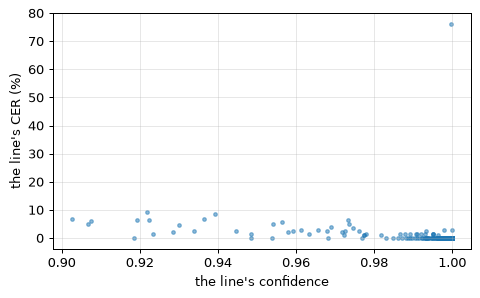

In [6]:
conf, errs, chars = [], [], []
for rows in results.values():
    for _, page in rows:
        for t, line in helpers.match_lines(truth_lines, page["lines"]):
            if line is None:
                continue
            e = carbon_ocr.text_errors([t["text"]], [line["text"]])[0]
            conf.append(line["confidence"])
            errs.append(e[0])
            chars.append(e[1])
conf, errs, chars = map(np.array, (conf, errs, chars))
print(f"{len(conf)} lines matched to their truth")
for lo, hi in [(0.99, 1.01), (0.95, 0.99), (0.9, 0.95), (0.8, 0.9), (0.0, 0.8)]:
    sel = (conf >= lo) & (conf < hi)
    if sel.any():
        print(f"confidence {lo:.2f} to {min(hi, 1):.2f}: {sel.sum():4} lines, CER {errs[sel].sum() / chars[sel].sum():7.2%}, "
              f"{(errs[sel] == 0).mean():6.1%} of them exact")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(conf, 100 * errs / np.maximum(chars, 1), s=8, alpha=0.5)
ax.set_xlabel("the line's confidence")
ax.set_ylabel("the line's CER (%)")
ax.grid(alpha=0.3);

A line's confidence goes down as its errors go up. Here, nearly every line at 0.99 or more is exact, and most lines under 0.99 hold an error. That makes it useful for triage: lines under a threshold go to a person, or to another reader. Measure where your threshold should be on your own pages, since a confident line can still hold an error and an unsure one can be right.

## Measuring a folder of your own

`evaluate` reads every image in a folder that has its text beside it (`page.png` and `page.txt`) and reports each page's CER and WER and the folder's. It streams the files to the engine's workers (notebook 3), so it reads any number of pages without holding them.

In [7]:
IMAGES = (".png", ".jpg", ".jpeg", ".bmp", ".pnm", ".pgm", ".ppm")


def evaluate(folder, engine):
    """Each image in `folder` with a .txt of its text beside it: (name, CER, WER) per page and over all."""
    files = sorted(f for f in Path(folder).iterdir() if f.suffix.lower() in IMAGES and f.with_suffix(".txt").exists())
    for f in files:
        engine.submit_file(f)
    rows, total = [], np.zeros(4, np.int64)
    for f in files:
        page = engine.next()
        e = carbon_ocr.text_errors([f.with_suffix(".txt").read_text(encoding="utf-8")], [page["text"]])[0]
        total += e
        rows.append((f.name, e[0] / e[1], e[2] / e[3]))
    return rows, (total[0] / total[1], total[2] / total[3])


# the sample pages and their texts, as a folder of your own would hold them
mine = Path("data/my-pages")
mine.mkdir(exist_ok=True)
for name in ["letter", "table", "banner", "receipt", "slide", "scan"]:
    src = pages[name]
    (mine / src.name).write_bytes(src.read_bytes())
    (mine / src.name).with_suffix(".txt").write_text(sample_pages.truth_text(src), encoding="utf-8")

rows, (cer, wer) = evaluate(mine, engine)
for name, c, w in rows:
    print(f"{name:12} CER {c:6.2%}  WER {w:6.2%}")
print(f"{'all':12} CER {cer:6.2%}  WER {wer:6.2%}")

banner.png   CER  0.25%  WER  0.00%
letter.png   CER  0.00%  WER  0.00%
receipt.png  CER  0.43%  WER  0.00%
scan.jpg     CER  0.00%  WER  0.00%
slide.png    CER  0.00%  WER  0.00%
table.png    CER  3.62%  WER  3.85%
all          CER  0.56%  WER  0.49%


The table's CER comes from its reading order: the engine reads its two header rows in an order of its own, and a CER over the page's text counts that. When order matters less than the lines' text, match lines by their boxes and score them one by one, as the confidence study above does (`helpers.line_cer`). To compare the engine's options or precisions on your pages, call `evaluate` with an engine for each:

In [8]:
for label, options in [("defaults", {}), ("justified", dict(justified=True)), ("FP16 files", dict(precision="fp16")),
                       ("block_order='model'", dict(block_order="model"))]:
    _, (cer, wer) = evaluate(mine, carbon_ocr.Engine(SET, **options))
    print(f"{label:20} CER {cer:6.2%}  WER {wer:6.2%}")

defaults             CER  0.56%  WER  0.49%


justified            CER  0.54%  WER  0.49%


FP16 files           CER  0.56%  WER  0.49%


block_order='model'  CER  0.56%  WER  0.49%
